In [1]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_row", 10)

print("Libraries Loaded Successfully!")

Libraries Loaded Successfully!


In [2]:
#Loading datasets
orders = pd.read_csv(r"D:\E-commerce_dataAnalysis\Python\data\orders.csv")
order_items = pd.read_csv(r"D:\E-commerce_dataAnalysis\Python\data\order_items.csv")
products = pd.read_csv(r"D:\E-commerce_dataAnalysis\Python\data\products.csv")
users = pd.read_csv(r"D:\E-commerce_dataAnalysis\Python\data\users.csv")

print("Datasets Loaded Successfully!")

Datasets Loaded Successfully!


In [3]:
#Number of rows and columns in each table
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Users:", users.shape)

Orders: (20000, 6)
Order Items: (43525, 7)
Products: (2000, 6)
Users: (10000, 6)


In [4]:
#Data preview (only first 5 rows)
print("ORDERS")
display(orders.head())

print("ORDER ITEMS")
display(order_items.head())

print("PRODUCTS")
display(products.head())

print("USERS")
display(users.head())

ORDERS


,order_id,user_id,order_date,order_status,total_amount,is_valid_sale
0,O00000001,U009310,2025-09-09 14:52:37.292731,processing,689.66,1
1,O00000002,U003247,2025-04-15 01:18:27.193404,completed,1666.85,1
2,O00000003,U007252,2025-04-27 15:37:48.008624,processing,665.06,1
3,O00000004,U008986,2025-10-04 20:35:22.204857,cancelled,689.50,0
4,O00000005,U008537,2024-11-13 08:15:18.498252,cancelled,860.50,0


ORDER ITEMS


,order_item_id,order_id,product_id,user_id,quantity,item_price,item_total
0,I00000001,O00000001,P001758,U009310,2,8.07,16.14
1,I00000002,O00000001,P001119,U009310,1,74.08,74.08
2,I00000003,O00000001,P001794,U009310,1,576.97,576.97
3,I00000004,O00000001,P001038,U009310,1,22.47,22.47
4,I00000005,O00000002,P000859,U003247,1,422.22,422.22


PRODUCTS


,product_id,product_name,category,brand,price,rating
0,P000001,Astra Be,Clothing,Astra,157.89,4.08
1,P000002,NeoTech Someone,Groceries,NeoTech,21.46,3.87
2,P000003,Acme Discuss,Sports,Acme,265.37,3.46
3,P000004,Nimbus South,Electronics,Nimbus,541.41,4.14
4,P000005,Astra Capital,Home & Kitchen,Astra,198.00,3.97


USERS


,user_id,name,email,gender,city,signup_date
0,U000001,Angel Hill,donaldgarcia@example.net,Other,New Roberttown,2025-03-13
1,U000002,Jesse Guzman,jennifermiles@example.com,Male,South Bridget,2024-03-05
2,U000003,Adam Shaffer,jpeterson@example.org,Male,Curtisfurt,2025-07-07
3,U000004,Melanie Munoz,blairamanda@example.com,Other,New Kellystad,2024-03-07
4,U000005,Janet Williams,kendragalloway@example.org,Female,South Joshuastad,2025-01-29


In [5]:
#Column names and data type
print("ORDERS")
orders.info()

print("\nORDER ITEMS")
order_items.info()

print("\nPRODUCTS")
products.info()

print("\nUSERS")
users.info()

ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       20000 non-null  object 
 1   user_id        20000 non-null  object 
 2   order_date     20000 non-null  object 
 3   order_status   20000 non-null  object 
 4   total_amount   20000 non-null  float64
 5   is_valid_sale  20000 non-null  int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 937.6+ KB

ORDER ITEMS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43525 entries, 0 to 43524
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_item_id  43525 non-null  object 
 1   order_id       43525 non-null  object 
 2   product_id     43525 non-null  object 
 3   user_id        43525 non-null  object 
 4   quantity       43525 non-null  int64  
 5   item_price     43525 non-null  floa

In [6]:
#Missing value checking
print("Orders missing values:")
print(orders.isnull().sum())

print("\nOrder Items missing value:")
print(order_items.isnull().sum())

print("\nProducts missing value:")
print(products.isnull().sum())

print("\nUsers missing value:")
print(users.isnull().sum())

Orders missing values:
order_id         0
user_id          0
order_date       0
order_status     0
total_amount     0
is_valid_sale    0
dtype: int64

Order Items missing value:
order_item_id    0
order_id         0
product_id       0
user_id          0
quantity         0
item_price       0
item_total       0
dtype: int64

Products missing value:
product_id      0
product_name    0
category        0
brand           0
price           0
rating          0
dtype: int64

Users missing value:
user_id        0
name           0
email          0
gender         0
city           0
signup_date    0
dtype: int64


In [7]:
#Duplicate value checking
print("Orders duplicates:", orders.duplicated().sum())
print("Order Items duplicates:", order_items.duplicated().sum())
print("Products duplicates:", products.duplicated().sum())
print("Users duplicates:", users.duplicated().sum())

Orders duplicates: 0
Order Items duplicates: 0
Products duplicates: 0
Users duplicates: 0


In [8]:
#Converting Date from String
orders["order_date"] = pd.to_datetime(orders["order_date"])
users["signup_date"] = pd.to_datetime(users["signup_date"])

print("Date columns converted successfully!")
print(orders["order_date"].dtype)
print(users["signup_date"].dtype)

Date columns converted successfully!
datetime64[ns]
datetime64[ns]


In [9]:
# Business rule: cancelled and returned orders are not real sales
orders["is_valid_sale"] = ~orders["order_status"].isin(["cancelled", "returned"]) # Assumption: processing orders are counted as valid sales

print(orders["is_valid_sale"].value_counts())
print("Gross revenue:", round(orders["total_amount"].sum(), 2))
print("Net revenue:", round(orders.loc[orders["is_valid_sale"], "total_amount"].sum(), 2))

is_valid_sale
True     12014
False     7986
Name: count, dtype: int64
Gross revenue: 11918668.95
Net revenue: 7193050.8


In [10]:
# Data validation checks
print("Orders with unknown user:", (~orders["user_id"].isin(users["user_id"])).sum())
print("Items with unknown order:", (~order_items["order_id"].isin(orders["order_id"])).sum())
print("Items with unknown product:", (~order_items["product_id"].isin(products["product_id"])).sum())

items_sum = order_items.groupby("order_id")["item_total"].sum().round(2)
check = orders.set_index("order_id")["total_amount"].round(2) - items_sum
print("Orders where total_amount != sum of items:", (check.abs() > 0.01).sum())

merged = orders.merge(users[["user_id", "signup_date"]], on="user_id")
print("Orders placed before signup date:", (merged["order_date"].dt.normalize() < merged["signup_date"]).sum())

Orders with unknown user: 0
Items with unknown order: 0
Items with unknown product: 0
Orders where total_amount != sum of items: 0
Orders placed before signup date: 9930


### Data Validation Summary
- All tables are consistent: no orphan records, and every order total matches its items.
- **Assumption:** cancelled and returned orders are excluded from net revenue. Shipped, processing and completed orders are counted as valid sales.
- **Limitation:** 9,930 orders (about 50%) are dated before the customer's signup date. This is likely a data-generation issue, so signup-based analysis (such as customer age or tenure) was avoided.

In [11]:
# Gross vs Net KPIs
valid = orders[orders["is_valid_sale"]]

kpi = pd.DataFrame({
    "Metric": ["Orders", "Revenue", "Average Order Value"],
    "Gross (all orders)": [len(orders), orders["total_amount"].sum(), orders["total_amount"].mean()],
    "Net (valid sales)": [len(valid), valid["total_amount"].sum(), valid["total_amount"].mean()]
}).round(2)

display(kpi)

,Metric,Gross (all orders),Net (valid sales)
0,Orders,20000.00,12014.00
1,Revenue,11918668.95,7193050.80
2,Average Order Value,595.93,598.72


In [12]:
#Basis ststistics, Numerical columns
print("ORDERS")
display(orders.describe())

print("ORDER Items")
display(order_items.describe())

print("PRODUCTS")
display(products.describe())

ORDERS


,order_date,total_amount
count,20000,20000.000000
mean,2024-12-06 19:27:11.857592064,595.933447
min,2024-01-01 00:14:17.631198,1.110000
25%,2024-06-19 04:22:49.692361216,111.355000
50%,2024-12-05 10:04:04.342068480,308.195000
75%,2025-05-27 04:33:50.669431552,768.195000
max,2025-11-14 23:17:25.548939,7950.740000
std,NaN,776.063336


ORDER Items


,quantity,item_price,item_total
count,43525.000000,43525.000000,43525.000000
mean,1.397312,196.636976,273.835013
std,0.660717,297.259224,471.585104
min,1.000000,1.110000,1.110000
25%,1.000000,36.400000,44.590000
50%,1.000000,83.170000,105.340000
75%,2.000000,208.050000,274.980000
max,3.000000,2338.130000,7014.390000


PRODUCTS


,price,rating
count,2000.000000,2000.000000
mean,200.342230,3.677615
std,302.742395,0.686478
min,1.110000,2.500000
25%,36.335000,3.070000
50%,84.220000,3.690000
75%,210.817500,4.250000
max,2338.130000,4.900000


In [13]:
#Categorical values, categories/status
print("Order Statuses:")
print(orders["order_status"].value_counts())

print("\nProduct Categories:")
print(products["category"].value_counts())

print("\nGenders:")
print(users["gender"].value_counts())

Order Statuses:
order_status
shipped       4113
returned      4066
completed     4021
cancelled     3920
processing    3880
Name: count, dtype: int64

Product Categories:
category
Clothing          213
Toys              213
Pet Supplies      212
Beauty            207
Electronics       203
Home & Kitchen    199
Books             194
Automotive        193
Groceries         183
Sports            183
Name: count, dtype: int64

Genders:
gender
Other     3419
Female    3334
Male      3247
Name: count, dtype: int64


In [14]:
#Period covered by the orders
print("Order date range:")
print("From:", orders["order_date"].min())
print("To:", orders["order_date"].max())

Order date range:
From: 2024-01-01 00:14:17.631198
To: 2025-11-14 23:17:25.548939


In [15]:
#Year and Month column from order_date
orders["year"] = orders["order_date"].dt.year
orders["month"] = orders["order_date"].dt.month
orders["month_name"] = orders["order_date"].dt.month_name()

display(orders[["order_date", "year", "month", "month_name"]].head())

,order_date,year,month,month_name
0,2025-09-09 14:52:37.292731,2025,9,September
1,2025-04-15 01:18:27.193404,2025,4,April
2,2025-04-27 15:37:48.008624,2025,4,April
3,2025-10-04 20:35:22.204857,2025,10,October
4,2024-11-13 08:15:18.498252,2024,11,November


In [16]:
# Valid sales only: cancelled and returned orders excluded
orders_valid = orders[orders["is_valid_sale"]].copy()
items_valid = order_items.merge(orders_valid[["order_id"]], on="order_id", how="inner")

print("Valid orders:", orders_valid.shape[0])
print("Valid order items:", items_valid.shape[0])

Valid orders: 12014
Valid order items: 26130


In [17]:
#How many orders came from each year
orders["year"].value_counts().sort_index()

year
2024    10769
2025     9231
Name: count, dtype: int64

In [18]:
#How orders are distributed across months
orders["month_name"].value_counts()


month_name
July        1854
March       1835
May         1810
August      1807
October     1792
            ... 
January     1767
June        1765
February    1639
November    1264
December     888
Name: count, Length: 12, dtype: int64

In [19]:
orders.groupby(["year", "month", "month_name"]).size().reset_index(name="orders")

,year,month,month_name,orders
0,2024,1,January,881
1,2024,2,February,814
2,2024,3,March,950
3,2024,4,April,928
4,2024,5,May,907
...,...,...,...,...
18,2025,7,July,898
19,2025,8,August,925
20,2025,9,September,897
21,2025,10,October,892


In [20]:
#Net revenue by Year (valid sales only)
orders_valid.groupby("year")["total_amount"].sum().round(2)

year
2024    3896909.06
2025    3296141.74
Name: total_amount, dtype: float64

In [21]:
#Monthly net revenue (valid sales only)
monthly_revenue = (orders_valid.groupby(["year", "month", "month_name"])["total_amount"].sum().reset_index().sort_values(["year", "month"]))

display(monthly_revenue)

,year,month,month_name,total_amount
0,2024,1,January,319814.03
1,2024,2,February,270451.48
2,2024,3,March,341429.57
3,2024,4,April,322338.42
4,2024,5,May,338527.03
...,...,...,...,...
18,2025,7,July,324208.65
19,2025,8,August,309080.83
20,2025,9,September,295167.99
21,2025,10,October,337920.69


In [22]:
# Net monthly revenue (valid sales only)
valid = orders[orders["is_valid_sale"]]
monthly_net = (valid.groupby(["year", "month", "month_name"])["total_amount"]
               .sum().reset_index().sort_values(["year", "month"]))
monthly_net["period"] = monthly_net["month_name"].str[:3] + " " + monthly_net["year"].astype(str)

display(monthly_net.tail(4))

,year,month,month_name,total_amount,period
19,2025,8,August,309080.83,Aug 2025
20,2025,9,September,295167.99,Sep 2025
21,2025,10,October,337920.69,Oct 2025
22,2025,11,November,172549.50,Nov 2025


In [23]:
#Which month generated the highest revenue
monthly_revenue.loc[monthly_revenue["total_amount"].idxmax()]

year                 2024
month                   7
month_name           July
total_amount    361515.21
Name: 6, dtype: object

In [24]:
#Which month generated the lowest revenue
monthly_revenue.loc[monthly_revenue["total_amount"].idxmin()]

year                2025
month                 11
month_name      November
total_amount    172549.5
Name: 22, dtype: object

In [25]:
#Complete month which generated the lowest revenue. November has only 14 days so it's not a complete month.
monthly_revenue_complete = monthly_revenue[~((monthly_revenue["year"] == 2025) & (monthly_revenue["month"] == 11))]

display(monthly_revenue_complete.loc[monthly_revenue_complete["total_amount"].idxmin()])

year                 2024
month                   2
month_name       February
total_amount    270451.48
Name: 1, dtype: object

In [26]:
#Net average order value (valid sales only)
average_order_value = orders_valid["total_amount"].mean()
print(f"Net Average Order Value: {average_order_value:.2f}")

Net Average Order Value: 598.72


In [27]:
#Mean vs Median (valid sales only)
median_order_value = orders_valid["total_amount"].median()
print(f"Net Median Order Value: {median_order_value:.2f}")

Net Median Order Value: 312.60


In [28]:
#Which order statuses contribute most to revenue?
revenue_by_status = (orders.groupby("order_status")["total_amount"].sum().sort_values(ascending=False))

display(revenue_by_status)

order_status
returned      2426918.02
shipped       2423866.56
completed     2419712.58
processing    2349471.66
cancelled     2298700.13
Name: total_amount, dtype: float64

In [29]:
#Net revenue by product category (valid sales only)
revenue_by_category = (items_valid.merge(products[["product_id", "category"]], on="product_id", how="left")
                       .groupby("category")["item_total"].sum().sort_values(ascending=False).round(2))

display(revenue_by_category)

category
Electronics       2971036.21
Automotive        1544960.64
Home & Kitchen     686010.77
Sports             558452.33
Clothing           429787.92
Beauty             339474.06
Toys               239090.48
Pet Supplies       211487.60
Books              159566.32
Groceries           53184.47
Name: item_total, dtype: float64

In [30]:
#Top 10 products by net revenue (valid sales only)
product_revenue = (items_valid.merge(products[["product_id", "product_name"]], on="product_id", how="left")
                   .groupby(["product_id", "product_name"])["item_total"].sum().sort_values(ascending=False).head(10).round(2))

display(product_revenue)

product_id  product_name    
P000910     Orion Group         37405.60
P001527     Willow Result       34602.14
P000731     Pulse Treat         33383.34
P001227     GreenLeaf System    32777.68
P000136     Zenith Phone        32549.70
P000198     Orion Face          32463.12
P000681     Acme Keep           32455.80
P001925     Willow Hospital     32178.24
P001049     Zenith Their        31999.60
P001448     Harbor Onto         31896.28
Name: item_total, dtype: float64

In [31]:
#Net revenue by brand (valid sales only)
brand_revenue = (items_valid.merge(products[["product_id", "brand"]], on="product_id", how="left")
                 .groupby("brand")["item_total"].sum().sort_values(ascending=False).round(2))

display(brand_revenue)

brand
Willow     786661.79
Orion      703486.27
Nimbus     686662.29
Zenith     623791.03
Acme       614579.91
             ...    
Harbor     551748.07
Pulse      550878.36
Solace     526795.65
Everest    503063.88
NeoTech    432548.41
Name: item_total, Length: 12, dtype: float64

In [32]:
#How many unique customers placed orders?
unique_customers = orders["user_id"].nunique()

print(f"Unique customers who placed orders are: {unique_customers}")

Unique customers who placed orders are: 8635


In [33]:
#Top 10 customers by net revenue (valid sales only)
top_customers = orders_valid.groupby("user_id")["total_amount"].sum().sort_values(ascending=False).head(10).round(2)

print(top_customers)

user_id
U009903    9791.56
U000006    9692.59
U004906    9538.69
U006469    8380.81
U005921    7471.96
U000564    7431.37
U004717    7216.09
U005803    7096.88
U008033    7096.12
U009076    7013.55
Name: total_amount, dtype: float64


In [34]:
#Average net revenue per customer (all customers who placed an order; customers with no valid sale count as 0)
active_customers = orders["user_id"].unique()
customer_revenue = orders_valid.groupby("user_id")["total_amount"].sum().reindex(active_customers, fill_value=0)

average_revenue_per_customer = customer_revenue.mean()

print(f"Average net revenue per customer: {average_revenue_per_customer:.2f}")
print(f"Customers with no valid sale: {(customer_revenue == 0).sum()}")

Average net revenue per customer: 833.01
Customers with no valid sale: 1663


In [35]:
#Average valid orders per customer (all customers who placed an order)
order_per_customer = orders_valid.groupby("user_id").size().reindex(active_customers, fill_value=0)

average_order_per_customer = order_per_customer.mean()

print(f"Average valid orders per customer: {average_order_per_customer:.2f}")

Average valid orders per customer: 1.39


In [36]:
#High order frequency but relatively low spending (valid sales only)
customer_analysis = orders_valid.groupby("user_id").agg(total_orders=("order_id", "count"), total_revenue=("total_amount", "sum"))

customer_analysis["avg_order_value"] = customer_analysis["total_revenue"] / customer_analysis["total_orders"]

display(customer_analysis.sort_values(["total_orders", "avg_order_value"], ascending=[False, True]).head(10).round(2))

,total_orders,total_revenue,avg_order_value
user_id,,,
U006660,7,2464.84,352.12
U001285,6,1304.23,217.37
U007598,6,1451.46,241.91
U005914,6,2029.94,338.32
U002279,6,2382.30,397.05
U008674,6,2435.77,405.96
U002203,6,2478.16,413.03
U007307,6,2670.16,445.03
U003572,6,2695.89,449.32


In [37]:
#Top 10 cities by net revenue (valid sales only)
city_revenue = (orders_valid.merge(users[["user_id", "city"]], on="user_id", how="left")
                .groupby("city")["total_amount"].sum().sort_values(ascending=False).head(10).round(2))

display(city_revenue)

city
North Michael         11807.43
East David            11491.60
North Williamville    10594.07
South Mary            10523.74
Lindatown              9917.62
Port James             9843.55
Johnsonchester         9817.55
Nolanborough           9791.56
South Ashley           9761.62
East Steven            9692.59
Name: total_amount, dtype: float64

In [38]:
#Which cities have the most customers?
city_customers = (users[users["user_id"].isin(orders["user_id"])].groupby("city")["user_id"].nunique().sort_values(ascending=False).head(10))

display(city_customers)

city
West Michelle       10
North Michael       10
Michaelmouth         9
West Jennifer        9
West Michael         9
Lake John            8
Lake Christopher     7
Brownmouth           7
South Ashley         7
East David           7
Name: user_id, dtype: int64

In [39]:

#Top 10 products by net quantity sold (valid sales only)
product_quantity = (items_valid.groupby("product_id")["quantity"].sum().sort_values(ascending=False).head(10).to_frame("total_quantity")
                    .merge(products[["product_id", "product_name"]], on="product_id", how="left"))

display(product_quantity)

,product_id,total_quantity,product_name
0,P000789,41,Zenith Game
1,P000027,40,Willow Evening
2,P000443,37,Astra Great
3,P001354,37,Harbor Development
4,P000311,36,Pulse Money
5,P001088,36,Everest Church
6,P001524,36,Zenith Along
7,P000380,36,Solace Social
8,P001392,36,NeoTech Civil
9,P001201,36,Astra Cell


In [40]:
#Which products have the highest average selling price?
product_avg_price = (order_items.groupby("product_id")["item_price"].mean().sort_values(ascending=False).head(10).to_frame("avg_selling_price").merge(products[["product_id", "product_name"]],on= "product_id", how= "left"))

display(product_avg_price)

,product_id,avg_selling_price,product_name
0,P001024,2338.13,Astra Pull
1,P000910,2337.85,Orion Group
2,P000136,2169.98,Zenith Phone
3,P001527,2035.42,Willow Result
4,P001375,1993.95,Astra Owner
5,P001183,1835.32,Nimbus Word
6,P000642,1816.28,Acme Group
7,P001744,1797.55,Acme Artist
8,P000021,1772.36,Willow Special
9,P000681,1708.20,Acme Keep


In [41]:
#Quantity vs order value (valid sales only)
quantity_order_value = (items_valid.groupby("order_id").agg(total_quantity=("quantity", "sum"), order_value=("item_total", "sum")))

display(quantity_order_value.head(10))

,total_quantity,order_value
order_id,,
O00000001,5,689.66
O00000002,4,1666.85
O00000003,4,665.06
O00000006,9,2258.34
O00000008,1,15.21
O00000011,3,1016.61
O00000013,1,15.87
O00000014,2,520.96
O00000016,1,127.42


In [42]:
#Correlation
correlation = quantity_order_value["total_quantity"].corr(quantity_order_value["order_value"])

print(f"Correlation: {correlation:.3f}")

Correlation: 0.510


In [43]:
#Product rating vs net revenue (valid sales only)
rating_revenue = (items_valid.groupby("product_id")["item_total"].sum().to_frame("total_revenue")
                  .merge(products[["product_id", "rating"]], on="product_id", how="left"))

display(rating_revenue.head(10))

,product_id,total_revenue,rating
0,P000001,1421.01,4.08
1,P000002,343.36,3.87
2,P000003,3715.18,3.46
3,P000004,7579.74,4.14
4,P000005,4356.00,3.97
5,P000006,521.08,3.20
6,P000007,2029.25,2.61
7,P000008,541.76,2.93
8,P000009,5569.96,4.44
9,P000010,5642.64,3.47


In [44]:
#Whether product rating and net revenue are associated.
rating_correlation = rating_revenue["rating"].corr(rating_revenue["total_revenue"])

print(f"Rating-Revenue Correlation: {rating_correlation:.3f}")

Rating-Revenue Correlation: -0.002


In [45]:
#Which categories have high revenue but relatively few products?
category_analysis = (products.groupby("category").agg(product_count=("product_id", "nunique")).merge(revenue_by_category.rename("total_revenue"), left_index=True, right_index=True).sort_values("total_revenue", ascending=False))

display(category_analysis)

,product_count,total_revenue
category,,
Electronics,203,2971036.21
Automotive,193,1544960.64
Home & Kitchen,199,686010.77
Sports,183,558452.33
Clothing,213,429787.92
Beauty,207,339474.06
Toys,213,239090.48
Pet Supplies,212,211487.60
Books,194,159566.32


In [46]:
#What is the distribution of order statuses?
status_distribution = orders["order_status"].value_counts().to_frame("order_count")
status_distribution["percentage"] = (status_distribution["order_count"]/len(orders)*100).round(2)

display(status_distribution)

,order_count,percentage
order_status,,
shipped,4113,20.56
returned,4066,20.33
completed,4021,20.10
cancelled,3920,19.60
processing,3880,19.40


In [47]:
#What the average order value by order status
aov_by_status = (orders.groupby("order_status")["total_amount"].mean().sort_values(ascending=False))

display(aov_by_status.round(2))

order_status
processing    605.53
completed     601.77
returned      596.88
shipped       589.32
cancelled     586.40
Name: total_amount, dtype: float64

In [48]:
#Are cancelled/returned orders concentrated in particular categories or customers?
#Category part
cancelled_returned_category = (orders[orders["order_status"].isin(["cancelled", "returned"])].merge(order_items[["order_id", "product_id"]], on="order_id", how="inner").merge(products[["product_id", "category"]], on="product_id", how="left").groupby("category").size().sort_values(ascending=False).to_frame("cancelled_returned_orders"))

display(cancelled_returned_category)

,cancelled_returned_orders
category,
Pet Supplies,1935
Toys,1847
Clothing,1808
Beauty,1790
Books,1762
Electronics,1725
Home & Kitchen,1668
Sports,1666
Automotive,1635


In [49]:
#Are cancelled/returned orders concentrated in particular categories or customers?
#Customer part
customer_cancel_return = (orders[orders["order_status"].isin(["cancelled", "returned"])].groupby("user_id").size().sort_values(ascending=False).head(10).to_frame("cancelled_returned_orders"))

display(customer_cancel_return)

,cancelled_returned_orders
user_id,
U005173,6
U003889,5
U003485,5
U001279,5
U000684,5
U000088,5
U007488,5
U004751,5
U008940,5


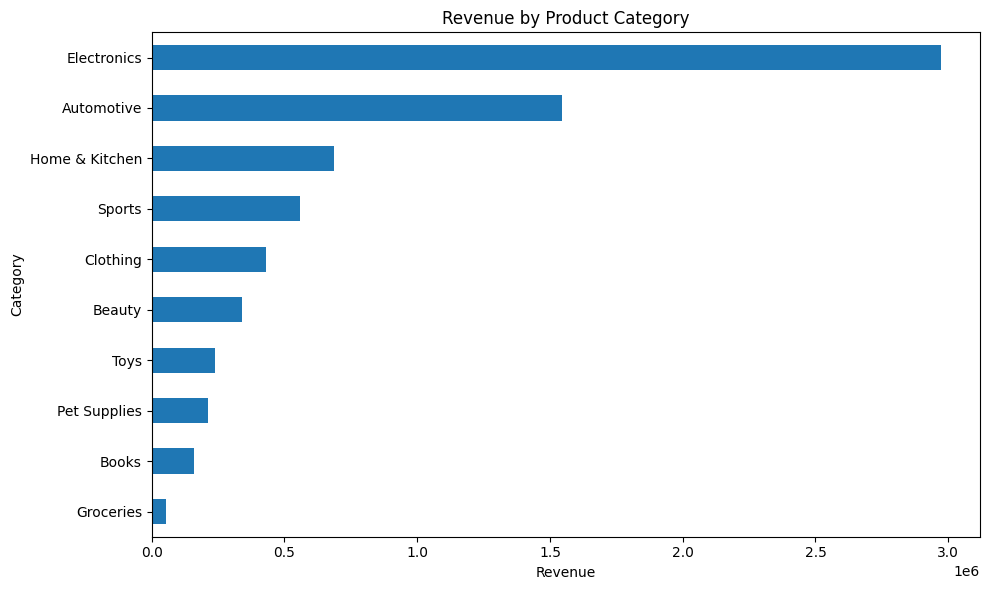

In [50]:
#Revenue by category
plt.figure(figsize=(10, 6))

revenue_by_category.sort_values().plot(kind="barh")

plt.title("Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()

plt.show()


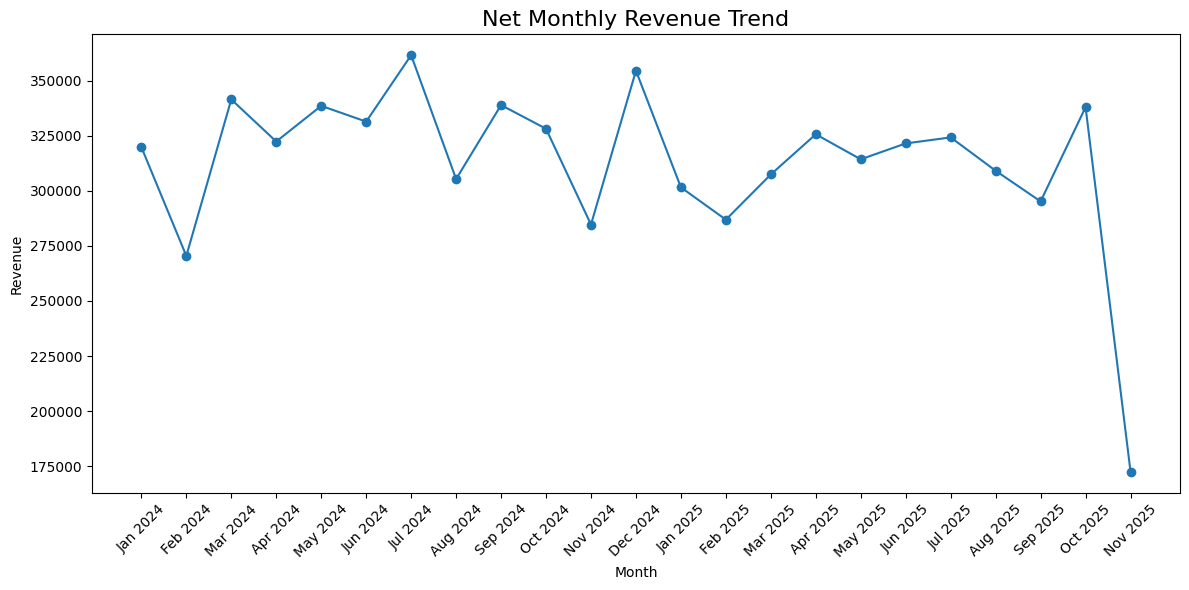

In [51]:
#Net Monthly Revenue Trend
monthly_revenue = (orders_valid.groupby(["year", "month", "month_name"])["total_amount"].sum().reset_index().sort_values(["year", "month"]))

monthly_revenue["period"] = (monthly_revenue["month_name"].str[:3]+ " " + monthly_revenue["year"].astype(str))

plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue["period"], monthly_revenue["total_amount"], marker="o")

plt.title("Net Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

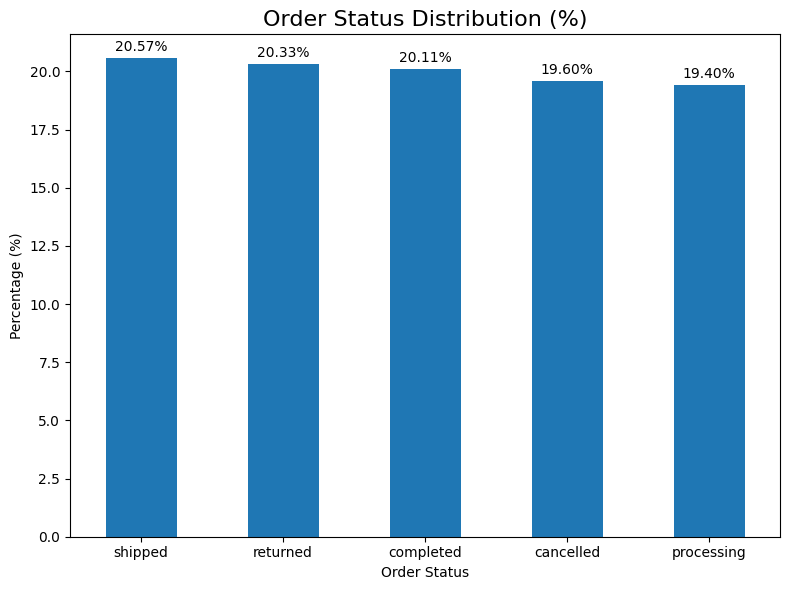

In [52]:
#Order Status Distribution
status_percentage = (orders["order_status"].value_counts(normalize=True).mul(100).sort_values(ascending=False))

plt.figure(figsize=(8, 6))

ax = status_percentage.plot(kind="bar")

plt.title("Order Status Distribution (%)", fontsize=16)
plt.xlabel("Order Status")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, labels=[f"{value:.2f}%" for value in container.datavalues], padding=3)

plt.tight_layout()
plt.show()

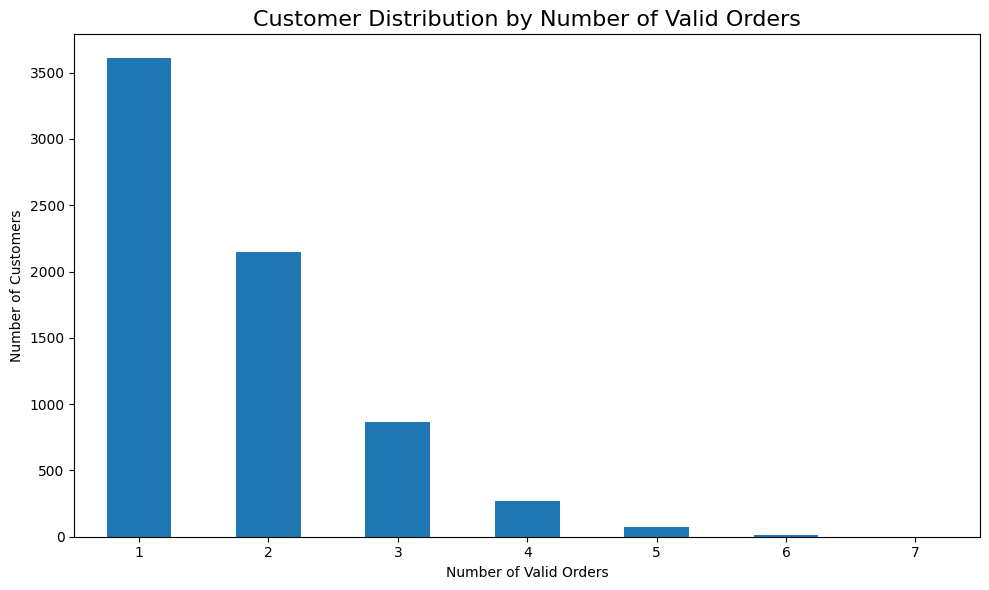

In [53]:
#Customer Behaivor
orders_per_customer = (orders_valid.groupby("user_id").size())

plt.figure(figsize=(10, 6))

orders_per_customer.value_counts().sort_index().plot(kind="bar")

plt.title("Customer Distribution by Number of Valid Orders", fontsize=16)
plt.xlabel("Number of Valid Orders")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

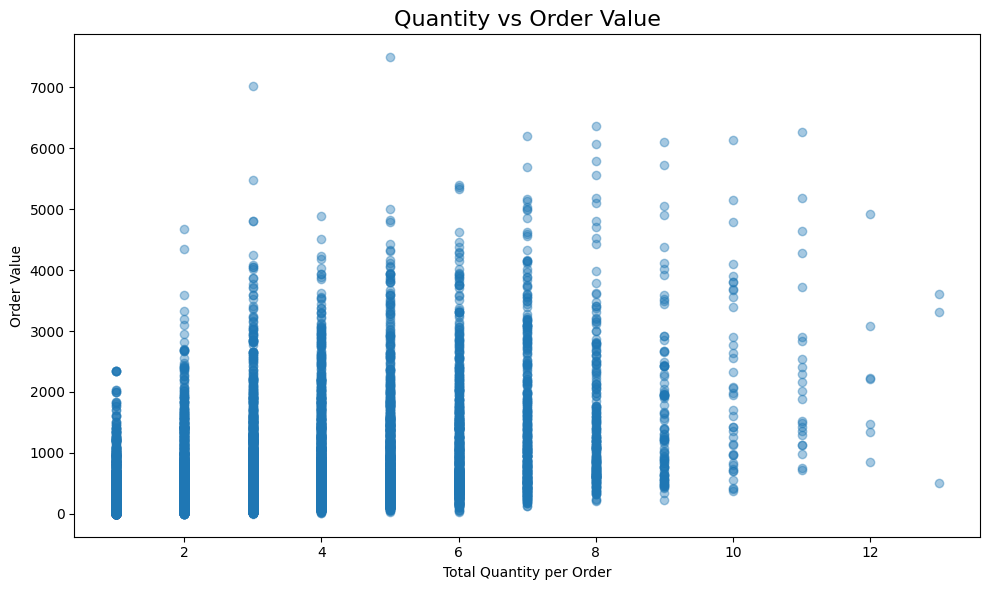

In [54]:
#Quantity VS Order Value
order_quantity_value = (items_valid.groupby("order_id").agg(total_quantity=("quantity", "sum"),order_value=("item_total", "sum")))

plt.figure(figsize=(10, 6))

plt.scatter(order_quantity_value["total_quantity"],order_quantity_value["order_value"],alpha=0.4)

plt.title("Quantity vs Order Value", fontsize=16)
plt.xlabel("Total Quantity per Order")
plt.ylabel("Order Value")

plt.tight_layout()
plt.show()

In [55]:
# Export cleaned orders for SQL
orders_clean = orders[["order_id", "user_id", "order_date", "order_status", "total_amount", "is_valid_sale"]].copy()
orders_clean["is_valid_sale"] = orders_clean["is_valid_sale"].astype(int)

orders_clean.to_csv(r"D:\E-commerce_dataAnalysis\Python\data\orders.csv", index=False)
print(orders_clean.shape)

(20000, 6)


In [56]:
revenue_by_category.to_csv(r"D:\E-commerce_dataAnalysis\Python\outputs\revenue_by_category.csv",header=True)

print("Revenue by category saved successfully!")

Revenue by category saved successfully!


In [57]:
monthly_revenue.to_csv(r"D:\E-commerce_dataAnalysis\Python\outputs\monthly_revenue.csv",index=False)

print("Monthly revenue saved successfully!")

Monthly revenue saved successfully!


In [58]:
order_status_output = (orders["order_status"].value_counts().rename_axis("order_status").reset_index(name="order_count"))

order_status_output["percentage"] = (order_status_output["order_count"]/ len(orders)* 100).round(2)

order_status_output.to_csv(r"D:\E-commerce_dataAnalysis\Python\outputs\order_status_analysis.csv",index=False)

print("Order status analysis saved successfully!")

Order status analysis saved successfully!


In [59]:
customer_summary = (orders_valid.groupby("user_id").agg(total_orders=("order_id", "count"),
                                                         total_revenue=("total_amount", "sum"),
                                                         avg_order_value=("total_amount", "mean"))
                    .sort_values(["total_orders", "user_id"], ascending=[False, True]).reset_index())

customer_summary.to_csv(r"D:\E-commerce_dataAnalysis\Python\outputs\customer_order_summary.csv", index=False)

print("Customer order summary saved successfully!")
print(customer_summary.shape)

Customer order summary saved successfully!
(6972, 4)


In [60]:
order_quantity_value.to_csv(r"D:\E-commerce_dataAnalysis\Python\outputs\quantity_vs_order_value.csv",index=True)

print("Quantity vs order value analysis saved successfully!")

Quantity vs order value analysis saved successfully!


## Key Insights and Recommendations

### Key Insights
1. **Revenue is overstated if cancelled and returned orders are counted.** Gross revenue is 11.92M, but net revenue (excluding cancelled and returned orders) is 7.19M. About 39.6% of revenue (4.73M) was lost to cancellations and returns.
2. **Order outcomes are almost evenly split.** Shipped 20.6%, returned 20.3%, completed 20.1%, cancelled 19.6% and processing 19.4%. The cancellation and return rate is about 40% in every product category, so it is not a category-specific problem.
3. **Electronics and Automotive drive the business.** They contribute 41.3% and 21.5% of net revenue, so together they account for about 63%. Groceries (0.7%) and Books (2.2%) contribute very little.
4. **Revenue is stable, with a small decline.** Net revenue peaked at 361.5K in July 2024 and was lowest at 270.5K in February 2024. The average for January to October 2025 (312.4K per month) is about 3.8% lower than the 2024 average (324.7K per month). November 2025 is a partial month and is excluded from this comparison.
5. **Most customers buy only once.** Of 6,972 customers with at least one valid order, 3,609 (52%) bought once and 3,363 repeat. 1,365 registered users never ordered, and 1,663 ordering customers had only cancelled or returned orders.
6. **A small group of customers brings disproportionate value.** The 79 High Value customers (over 5,000 net spending) are 0.9% of customers but 6.6% of net revenue. The 1,009 Medium Value customers bring 41.8%.
7. **Average order value is pulled up by large orders.** The mean is 598.72 but the median is only 312.60.
8. **Rating does not drive sales.** Product rating and revenue have almost no correlation (-0.002). Larger orders do contain more items (quantity vs order value correlation 0.51).
9. **No product or brand dominates.** The top 10 products make up only 4.6% of net revenue, and the 12 brands each hold between 6% and 11%.

### Recommendations
- Investigate why 4 in 10 orders end up cancelled or returned, because reducing this by even a few points would raise revenue more than any new marketing.
- Protect and grow Electronics and Automotive, and review whether Groceries and Books are worth keeping in the catalogue.
- Build a loyalty or second-purchase offer for the 3,609 one-time customers.
- Launch a re-activation campaign for the 1,365 registered users who never ordered.
- Give the 79 High Value customers a special program (early access, priority support).
- Report revenue as net revenue in all dashboards, with gross revenue shown separately.

### Data limitations
- 9,930 orders (about 50%) are dated before the customer's signup date, so customer tenure analysis was avoided.
- Order statuses are split almost evenly across all five values, which is unusual for real sales data and suggests the dataset is synthetic. Treat the cancellation rate as a feature of this dataset, not a benchmark.
- Cities are very fragmented (7,755 cities for 10,000 users), so city-level rankings are based on very few customers.